## CSE258 ASSIGNMENT 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

import ast
import gzip
from pathlib import Path

from itertools import islice

from scipy.stats import spearmanr

In [2]:
import warnings
import pandas as pd

warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)

## Introduction

General intro info goes here

### Introduction to Columns

`col1`: 

## The Data

In [3]:
user_items_path = Path("australian_users_items.json") / "australian_users_items.json"
user_item_columns = [
    "user_id",
    "item_id",
    "item_name",
    "playtime_forever",
    "playtime_2weeks",
]
user_item_batches = []

with user_items_path.open(encoding="utf-8") as item_file:
    while profile_lines := list(islice(item_file, 1_000)):
        rows = []
        for line in profile_lines:
            profile = ast.literal_eval(line)
            for item in profile["items"]:
                rows.append(
                    (
                        profile["user_id"],
                        item["item_id"],
                        item["item_name"],
                        item["playtime_forever"],
                        item["playtime_2weeks"],
                    )
                )
        user_item_batches.append(
            pd.DataFrame.from_records(rows, columns=user_item_columns)
        )

user_items = pd.concat(user_item_batches, ignore_index=True)
del user_item_batches
user_items.head()


,user_id,item_id,item_name,playtime_forever,playtime_2weeks
0,76561197970982479,10,Counter-Strike,6,0
1,76561197970982479,20,Team Fortress Classic,0,0
2,76561197970982479,30,Day of Defeat,7,0
3,76561197970982479,40,Deathmatch Classic,0,0
4,76561197970982479,50,Half-Life: Opposing Force,0,0


In [4]:
reviews_path = Path("australian_user_reviews.json.gz")
review_rows = []

with gzip.open(reviews_path, "rt", encoding="utf-8") as review_file:
    for line in review_file:
        profile = ast.literal_eval(line)
        for review in profile["reviews"]:
            review_rows.append({"user_id": profile["user_id"], **review})

reviews = pd.DataFrame.from_records(review_rows)
reviews.head()

,user_id,funny,posted,last_edited,item_id,helpful,recommend,review
0,76561197970982479,,"Posted November 5, 2011.",,1250,No ratings yet,True,Simple yet with great replayability. In my opi...
1,76561197970982479,,"Posted July 15, 2011.",,22200,No ratings yet,True,It's unique and worth a playthrough.
2,76561197970982479,,"Posted April 21, 2011.",,43110,No ratings yet,True,Great atmosphere. The gunplay can be a bit chu...
3,js41637,,"Posted June 24, 2014.",,251610,15 of 20 people (75%) found this review helpful,True,I know what you think when you see this title ...
4,js41637,,"Posted September 8, 2013.",,227300,0 of 1 people (0%) found this review helpful,True,For a simple (it's actually not all that simpl...


## EDA

User Item Dimensions: (5153209, 5)
Review Dimensions: (59305, 8)

Number of unique users: 25458
Number of unique games: 3682

Playtime statistics: 
count    5.153209e+06
mean     9.914951e+02
std      5.418204e+03
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+01
75%      3.550000e+02
max      6.427730e+05
Name: playtime_forever, dtype: float64

Recommendation distribution
recommend
True     52473
False     6832
Name: count, dtype: int64


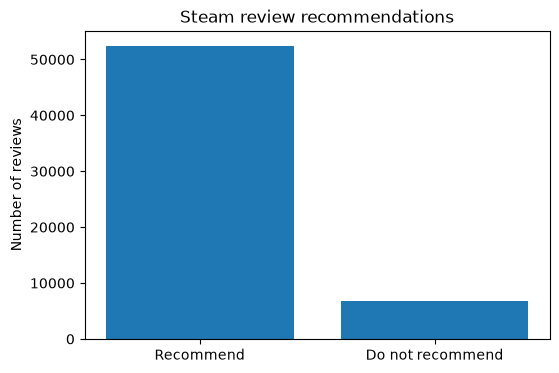

In [5]:
print(f"User Item Dimensions: {user_items.shape}")
print(f"Review Dimensions: {reviews.shape}")

print(f"\nNumber of unique users: {len(reviews['user_id'].unique())}")
print(f"Number of unique games: {len(reviews['item_id'].unique())}")

print("\nPlaytime statistics: ")
print(user_items["playtime_forever"].describe())

print("\nRecommendation distribution")
print(reviews["recommend"].value_counts())

counts = reviews["recommend"].value_counts().reindex([True, False], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Recommend", "Do not recommend"], counts.to_numpy())
ax.set_title("Steam review recommendations")
ax.set_ylabel("Number of reviews")
plt.show()

TODO: why we are merging

In [6]:
keys = ["user_id", "item_id"]

# Keeps only highest playtime review (latest) in the case of duplicate (user, item) review pairs
user_items_deduped = user_items.sort_values(
    "playtime_forever", ascending=False, kind="stable"
).drop_duplicates(subset=keys, keep="first")

merged_deduped = user_items_deduped.merge(
    reviews.drop_duplicates(),
    on=keys,
    how="left",
    validate="one_to_one",
)

Filter to only keep reviews where users actually played the game

In [7]:
# Keep only playtimes greater than 0
non_zero_playtimes = merged_deduped[merged_deduped["playtime_forever"] > 0].reset_index(
    drop="True"
)
non_zero_playtimes

,user_id,item_id,item_name,playtime_forever,playtime_2weeks,funny,posted,last_edited,helpful,recommend,review
0,wolop,4000,Garry's Mod,642773,7299,1 person found this review funny,"Posted July 3, 2011.",,2 of 2 people (100%) found this review helpful,True,Like buiding well you might like this
1,Evilutional,212200,Mabinogi,635295,0,NaN,NaN,NaN,NaN,NaN,NaN
2,76561198019826668,42710,Call of Duty: Black Ops - Multiplayer,632452,8126,NaN,NaN,NaN,NaN,NaN,NaN
3,76561198039832932,4000,Garry's Mod,613411,588,,"Posted July 9, 2015.",,No ratings yet,True,man this game RULES THANKS GARRY
4,tsunamitad,72200,Universe Sandbox,600068,0,461 people found this review funny,"Posted May 18, 2015.",,668 of 722 people (93%) found this review helpful,True,What can I say?1 hour of gameplay to explore t...
...,...,...,...,...,...,...,...,...,...,...,...
3246347,76561198310819422,432150,They Came From The Moon,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246348,76561198312638244,100,Counter-Strike: Condition Zero Deleted Scenes,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246349,76561198312638244,320,Half-Life 2: Deathmatch,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246350,76561198312638244,400040,ShareX,1,0,NaN,NaN,NaN,NaN,NaN,NaN


Keep only rows that have recommendations 

In [8]:
has_recommendation = non_zero_playtimes[~non_zero_playtimes["recommend"].isna()]
has_recommendation

,user_id,item_id,item_name,playtime_forever,playtime_2weeks,funny,posted,last_edited,helpful,recommend,review
0,wolop,4000,Garry's Mod,642773,7299,1 person found this review funny,"Posted July 3, 2011.",,2 of 2 people (100%) found this review helpful,True,Like buiding well you might like this
3,76561198039832932,4000,Garry's Mod,613411,588,,"Posted July 9, 2015.",,No ratings yet,True,man this game RULES THANKS GARRY
4,tsunamitad,72200,Universe Sandbox,600068,0,461 people found this review funny,"Posted May 18, 2015.",,668 of 722 people (93%) found this review helpful,True,What can I say?1 hour of gameplay to explore t...
6,shinomegami,8500,EVE Online,530882,0,"2,598 people found this review funny","Posted November 20, 2015.",,"2,200 of 2,593 people (85%) found this review ...",True,"When a player quits EVE and goes to WoW, the a..."
8,ThisIsWhereIGetOff,4000,Garry's Mod,495058,161,,"Posted September 12, 2014.",,No ratings yet,True,"Garry's mod, Best mod in this whole dumb world..."
...,...,...,...,...,...,...,...,...,...,...,...
3211593,TheofficalSneakyJew,362280,Mortal Kombat: Legacy II,1,0,,"Posted July 11, 2015.",,No ratings yet,True,Great movie should make it a downloadable file...
3213445,lodesofemone,420,Half-Life 2: Episode Two,1,0,,"Posted August 17, 2013.",,No ratings yet,True,"Amazing, lives up to expectations of all the o..."
3213968,76561198093711678,374570,Kung Fury,1,0,,"Posted June 6, 2015.",,No ratings yet,True,SOMEONE HAD FUN WRITING THE SCRIPT FOR THIS!!!
3223049,badsama,400,Portal,1,0,,"Posted December 27, 2011.",,No ratings yet,True,"I really like this game, but I couldn't find t..."


We want to subset our data to contain only games with a certain number of reviews.

In [9]:
review_counts = has_recommendation.groupby("item_id")["recommend"].count()

coverage = pd.DataFrame(
    {
        "games_kept": (review_counts >= cutoff).sum(),
        "share_of_games": (review_counts >= cutoff).mean(),
    }
    for cutoff in [10, 20, 40, 100]
)
coverage.index = pd.Index([10, 20, 40, 100], name="min_reviews")
coverage

,games_kept,share_of_games
min_reviews,,
10,619,0.200844
20,369,0.119727
40,195,0.063271
100,78,0.025308


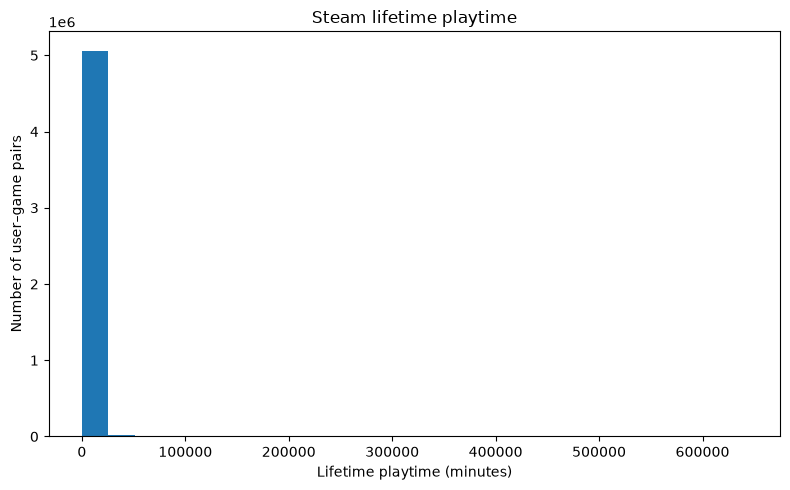

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(merged_deduped["playtime_forever"].dropna(), bins=25)

ax.set_title("Steam lifetime playtime")
ax.set_xlabel("Lifetime playtime (minutes)")
ax.set_ylabel("Number of user–game pairs")

plt.tight_layout()
plt.show()

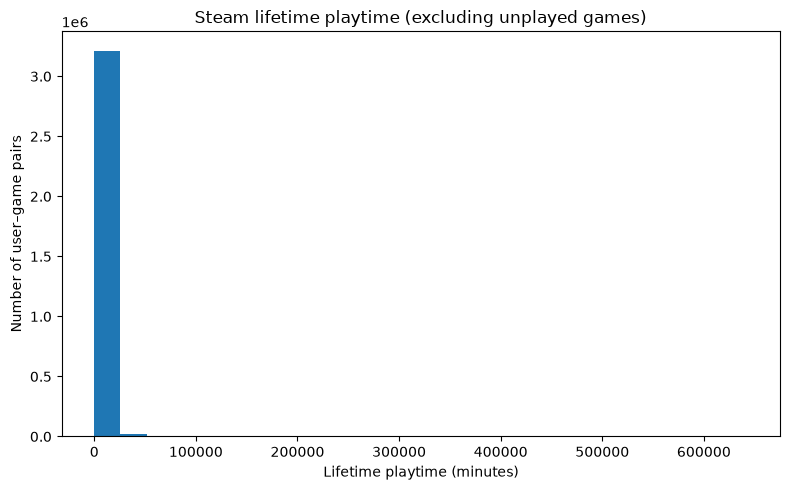

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(non_zero_playtimes["playtime_forever"].dropna(), bins=25)

ax.set_title("Steam lifetime playtime (excluding unplayed games)")
ax.set_xlabel("Lifetime playtime (minutes)")
ax.set_ylabel("Number of user–game pairs")

plt.tight_layout()
plt.show()

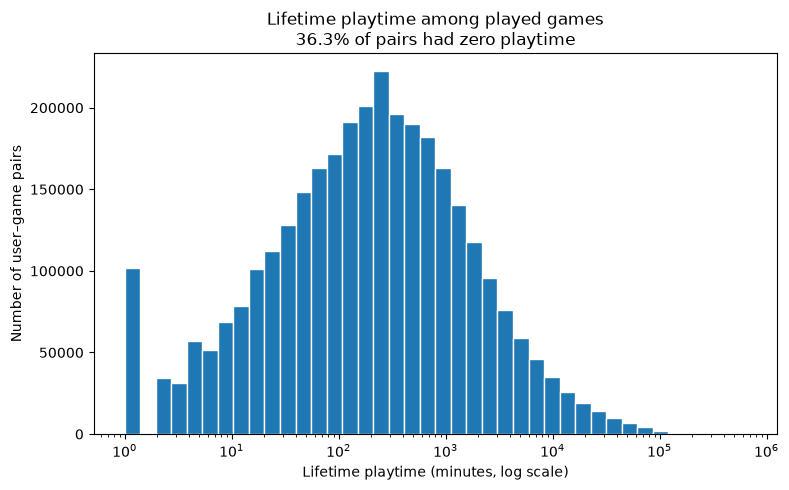

In [12]:
playtime = merged_deduped["playtime_forever"].dropna()
positive = playtime[playtime > 0]
zero_share = (playtime == 0).mean()

bins = np.geomspace(positive.min(), positive.max(), num=41)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(positive, bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Lifetime playtime (minutes, log scale)")
ax.set_ylabel("Number of user–game pairs")
ax.set_title(
    f"Lifetime playtime among played games\n{zero_share:.1%} of pairs had zero playtime"
)

plt.tight_layout()
plt.show()

### Is there a correlation between the number of hours played in a game, and whether a recommendation is positive or not?

                  mean  count
playtime_bin                 
0-1           0.638871   3046
1-5            0.82867   6111
5-10          0.889389   4665
10-25         0.917294   7835
25-50         0.922064   5697
50-100        0.928297   4951
100-400       0.931064   7108
400+          0.933419   4686


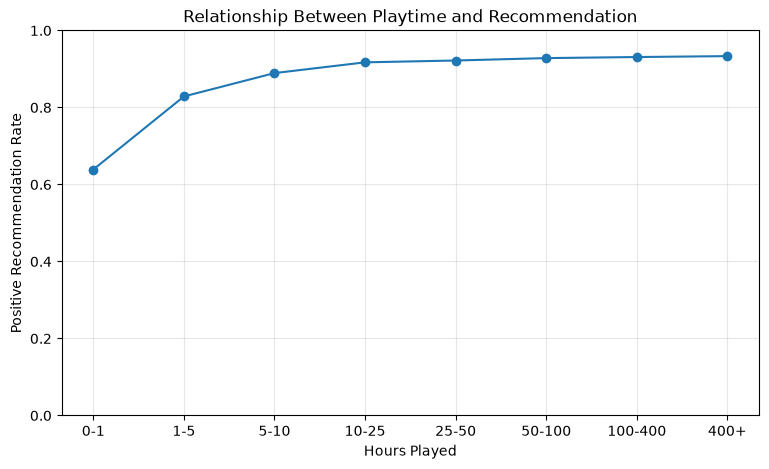

In [13]:
reviewed = has_recommendation.dropna(subset=["recommend"]).copy()

reviewed["hours"] = reviewed["playtime_forever"] / 60

bins = [0, 1, 5, 10, 25, 50, 100, 400, float("inf")]
labels = ["0-1", "1-5", "5-10", "10-25", "25-50", "50-100", "100-400", "400+"]

reviewed["playtime_bin"] = pd.cut(
    reviewed["hours"], bins=bins, labels=labels, include_lowest=True
)

results = reviewed.groupby("playtime_bin", observed=True)["recommend"].agg(
    ["mean", "count"]
)

print(results)

plt.figure(figsize=(9, 5))

plt.plot(results.index.astype(str), results["mean"], marker="o")

plt.xlabel("Hours Played")
plt.ylabel("Positive Recommendation Rate")
plt.title("Relationship Between Playtime and Recommendation")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

### Does median game time have an association with positive recommendation rate?

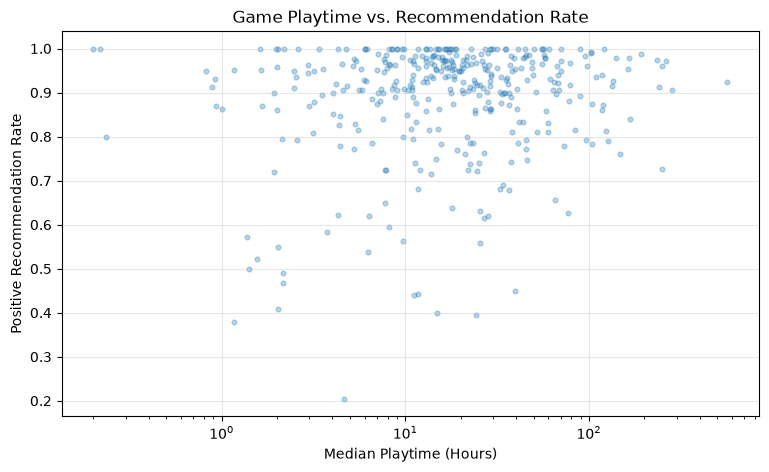

In [14]:
# Aggregate by game
game_stats = (
    reviewed.groupby("item_id")
    .agg(
        median_playtime=("playtime_forever", "median"),
        recommend_rate=("recommend", "mean"),
        review_count=("recommend", "count"),
    )
    .reset_index()
)

# Require at least 20 reviews per game
game_stats = game_stats[game_stats["review_count"] >= 20]


# Convert minutes to hours
game_stats["median_hours"] = game_stats["median_playtime"] / 60

plt.figure(figsize=(9, 5))

plt.scatter(game_stats["median_hours"], game_stats["recommend_rate"], alpha=0.3, s=12)

plt.xscale("log")
plt.xlabel("Median Playtime (Hours)")
plt.ylabel("Positive Recommendation Rate")
plt.title("Game Playtime vs. Recommendation Rate")
plt.grid(alpha=0.3)
plt.show()

In [29]:
rho, p_value = spearmanr(
    game_stats["median_hours"].to_numpy(dtype=float, na_value=np.nan),
    game_stats["recommend_rate"].to_numpy(dtype=float, na_value=np.nan),
)

print(f"Rho value: {rho}")
print(f"P-value: {p_value}")

Rho value: 0.061243295661417695
P-value: 0.24057303441215117


From the given $\rho = 0.0612$, we would conclude that there is practically no real monotonic association between `median_playtime (hours)` and `Positive Recommendation Rate`.
Since p-val > 0.05, we fail to reject the null hypothesis.

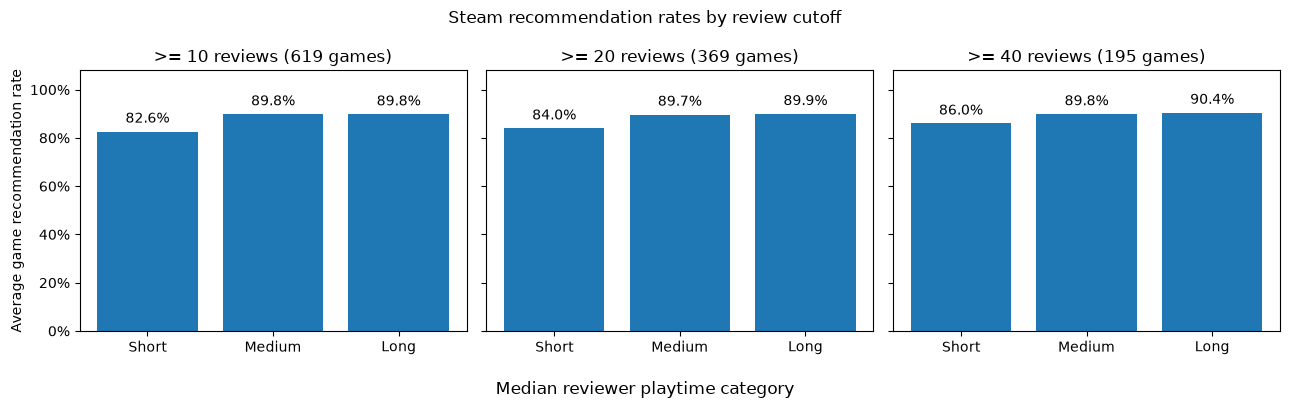

In [17]:
from matplotlib.ticker import PercentFormatter

all_game_stats = reviewed.groupby("item_id", as_index=False).agg(
    median_minutes=("playtime_forever", "median"),
    recommend_rate=("recommend", "mean"),
    review_count=("recommend", "count"),
)
all_game_stats["median_hours"] = all_game_stats["median_minutes"] / 60

# Define the playtime categories once using games with more than 10 reviews.
eligible = all_game_stats.loc[all_game_stats["review_count"] >= 10].copy()
q25, q75 = eligible["median_hours"].quantile([0.25, 0.75])

eligible["length_group"] = pd.cut(
    eligible["median_hours"],
    bins=[-np.inf, q25, q75, np.inf],
    labels=["Short", "Medium", "Long"],
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for ax, cutoff in zip(axes, [10, 20, 40]):
    subset = eligible.loc[eligible["review_count"] >= cutoff]
    rates = subset.groupby("length_group", observed=False)["recommend_rate"].mean()

    bars = ax.bar(rates.index.astype(str), rates.to_numpy())
    ax.bar_label(bars, labels=[f"{rate:.1%}" for rate in rates], padding=4)
    ax.set_title(f">= {cutoff} reviews ({len(subset)} games)")
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

axes[0].set_ylabel("Average game recommendation rate")
fig.supxlabel("Median reviewer playtime category")
fig.suptitle("Steam recommendation rates by review cutoff")

plt.tight_layout()
plt.show()

## Modeling

In [18]:
from collections import defaultdict
from scipy import sparse
import torch
import torch.nn.functional as F

In [19]:
print(torch.__version__)
print(torch.tensor([1, 2]) + 1)

2.15.0+cpu
tensor([2, 3])


In [20]:
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
assert {"user_id", "item_id", "playtime_forever", "recommend"}.issubset(
    merged_deduped.columns
)

Device: cpu


In [22]:
data = merged_deduped.copy()
data["user_id"] = data["user_id"].astype(str)
data["item_id"] = data["item_id"].astype(str)
data["playtime_forever"] = (
    pd.to_numeric(data["playtime_forever"], errors="coerce").fillna(0).clip(lower=0)
)
# Nullable Boolean handles True / False / NaN (do not fill missing with False).
data["recommend"] = data["recommend"].astype("boolean")
keys = ["user_id", "item_id"]
conflicts = data.dropna(subset=["recommend"]).groupby(keys)["recommend"].nunique()
print("Pairs with conflicting review labels:", int((conflicts > 1).sum()))
if (conflicts > 1).any():
    raise ValueError(
        "Resolve conflicting review labels for the same user-game pair first."
    )
data = (
    data.sort_values("playtime_forever", ascending=False)
    .drop_duplicates(keys)
    .reset_index(drop=True)
)
print(
    "Pairs:",
    len(data),
    "Users:",
    data.user_id.nunique(),
    "Games:",
    data.item_id.nunique(),
)
print(
    "Known reviews:",
    data.recommend.notna().sum(),
    "Positive:",
    (data.recommend == True).sum(),
    "Negative:",
    (data.recommend == False).sum(),
)


Pairs with conflicting review labels: 0
Pairs: 5094082 Users: 70912 Games: 10978
Known reviews: 44186 Positive: 39269 Negative: 4917


In [23]:
positive_reviews = data.loc[data['recommend'] == True, keys]
counts = positive_reviews.groupby('user_id').size()
eligible_users = counts[counts >= 3].index
print('Evaluation-eligible users (>=3 positive reviews):', len(eligible_users))
if len(eligible_users) < 25:
    print('WARNING: very small evaluation population; metrics will be noisy. Consider a review-label prediction task if this persists.')

held_val, held_test = [], []
for uid, rows in positive_reviews[positive_reviews.user_id.isin(eligible_users)].groupby('user_id', sort=False):
    chosen = rng.choice(rows['item_id'].to_numpy(), size=2, replace=False)
    held_val.append((uid, chosen[0]))
    held_test.append((uid, chosen[1]))
val_pairs = pd.DataFrame(held_val, columns=keys)
test_pairs = pd.DataFrame(held_test, columns=keys)
holdout_pairs = pd.concat([val_pairs, test_pairs], ignore_index=True)
train = data.merge(holdout_pairs.assign(_held=True), on=keys, how='left')
train = train[train['_held'].isna()].drop(columns='_held').reset_index(drop=True)
assert len(train) + len(holdout_pairs) == len(data)
assert not train.merge(holdout_pairs, on=keys, how='inner').shape[0]
print('Train pairs:', len(train), 'Validation positives:', len(val_pairs), 'Test positives:', len(test_pairs))


Evaluation-eligible users (>=3 positive reviews): 4894
Train pairs: 5084294 Validation positives: 4894 Test positives: 4894


In [24]:
user_ids = train.user_id.drop_duplicates().to_list()
item_ids = train.item_id.drop_duplicates().to_list()
u2i = {x: j for j,x in enumerate(user_ids)}
g2i = {x: j for j,x in enumerate(item_ids)}
train['u'] = train.user_id.map(u2i).astype('int32')
train['i'] = train.item_id.map(g2i).astype('int32')
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

train_seen = defaultdict(set)
for u,i in zip(train.u.to_numpy(), train.i.to_numpy()):
    train_seen[int(u)].add(int(i))

# Eval users/games must exist in train for ranking.
def mapped_targets(pairs):
    out = pairs.copy()
    out['u'] = out.user_id.map(u2i)
    out['i'] = out.item_id.map(g2i)
    missing = out[['u','i']].isna().any(axis=1).sum()
    print(f'Holdouts not representable in train catalog: {missing}/{len(out)}')
    return out.dropna(subset=['u','i']).astype({'u':'int32','i':'int32'})

val_eval = mapped_targets(val_pairs)
test_eval = mapped_targets(test_pairs)

played = train[train.playtime_forever > 0]
med = played.groupby('i').playtime_forever.median().div(60)
q25, q75 = med.quantile([.25,.75])
length_by_item = pd.Series('Unknown/zero-play', index=np.arange(N_ITEMS), dtype='object')
length_by_item.loc[med.index] = pd.cut(med, [-np.inf,q25,q75,np.inf], labels=['Short','Medium','Long']).astype(str).to_numpy()
print(f'Training length cutoffs: {q25:.2f}, {q75:.2f} hours')
print(length_by_item.value_counts())


Holdouts not representable in train catalog: 0/4894
Holdouts not representable in train catalog: 1/4894
Training length cutoffs: 0.45, 3.52 hours
Medium               4986
Short                2550
Long                 2509
Unknown/zero-play     932
Name: count, dtype: int64


In [25]:
# Popularity counts players with positive training playtime; never use held-out interactions.
item_pop = np.bincount(played.i.to_numpy(), minlength=N_ITEMS).astype(float)
# A tiny deterministic tie-breaker by item index makes all model comparisons reproducible.

def evaluate(score_fn, targets, k=10, batch_users=64):
    targets = targets.groupby('u')['i'].apply(set).to_dict()
    ranks, lists = [], []
    valid_u = sorted(targets)
    for start in range(0, len(valid_u), batch_users):
        us = valid_u[start:start+batch_users]
        s = np.asarray(score_fn(np.array(us, dtype=np.int64)), dtype=np.float64).copy()
        assert s.shape == (len(us), N_ITEMS)
        s[~np.isfinite(s)] = -np.inf
        for row,u in enumerate(us):
            if train_seen[u]:
                s[row, list(train_seen[u])] = -np.inf
        kk = min(k, N_ITEMS)
        top = np.argsort(-s, axis=1, kind='stable')[:, :kk]
        for row,u in enumerate(us):
            rec = top[row].tolist()
            lists.append(rec)
            ranks.append([j+1 for j,i in enumerate(rec) if i in targets[u]])
    recalls = [len(r) / len(targets[u]) for r,u in zip(ranks, valid_u)]
    ndcgs = [sum(1 / np.log2(rank+1) for rank in r) /
             sum(1 / np.log2(j+2) for j in range(min(k,len(targets[u]))))
             for r,u in zip(ranks,valid_u)]
    flat = np.array([i for rec in lists for i in rec], dtype=int)
    result = {
        f'Recall@{k}': float(np.mean(recalls)) if recalls else np.nan,
        f'NDCG@{k}': float(np.mean(ndcgs)) if ndcgs else np.nan,
        'Catalog coverage': float(len(np.unique(flat))/N_ITEMS) if len(flat) else np.nan,
        'Short share': float(np.mean(length_by_item.iloc[flat].to_numpy() == 'Short')) if len(flat) else np.nan,
        'Mean log(1+item popularity)': float(np.log1p(item_pop[flat]).mean()) if len(flat) else np.nan,
        'Users evaluated': len(valid_u)
    }
    return result

def popularity_scores(user_batch):
    return np.broadcast_to(item_pop, (len(user_batch), N_ITEMS))

baseline_val = evaluate(popularity_scores, val_eval)
print('Popularity validation:', baseline_val)

Popularity validation: {'Recall@10': 0.27973028197793215, 'NDCG@10': 0.19468619839031612, 'Catalog coverage': 0.008836658467705202, 'Short share': 0.0001021659174499387, 'Mean log(1+item popularity)': 9.78394830761012, 'Users evaluated': 4894}


In [26]:
# Build different positive pools from *train only*.
train['review_pos'] = (train.recommend == True).fillna(False).astype(bool)
train['review_neg'] = (train.recommend == False).fillna(False).astype(bool)

binary_pos = train[train.playtime_forever > 0][['u','i','playtime_forever']].copy()
review_pos = train[((train.playtime_forever > 0) & ~train.review_neg) | train.review_pos][['u','i','playtime_forever']].copy()
review_neg_by_user = defaultdict(list)
for u,i in zip(train.loc[train.review_neg,'u'], train.loc[train.review_neg,'i']):
    review_neg_by_user[int(u)].append(int(i))

print('Binary positive interactions:',len(binary_pos),
      'Review-aware positive interactions:',len(review_pos),
      'Explicit negative reviews:',int(train.review_neg.sum()))

def get_sampling_weights(pos, mode):
    if mode == 'weighted':
        hours = pos.playtime_forever.to_numpy(dtype=float)/60
        weights = np.log1p(hours)
        # Prevent very long sessions from dominating; positive samples need nonzero weight.
        weights = np.clip(weights, 0.1, np.quantile(weights, .99))
        return weights / weights.sum()
    return None

class BPR(torch.nn.Module):
    def __init__(self, n_users, n_items, dim=32):
        super().__init__()
        self.user = torch.nn.Embedding(n_users, dim)
        self.item = torch.nn.Embedding(n_items, dim)
        torch.nn.init.normal_(self.user.weight, std=.05)
        torch.nn.init.normal_(self.item.weight, std=.05)
    def forward(self, u, p, n):
        return (self.user(u)*(self.item(p)-self.item(n))).sum(dim=-1)
    @torch.no_grad()
    def score_users(self, users):
        return (self.user.weight[torch.as_tensor(users,device=DEVICE)] @ self.item.weight.T).cpu().numpy()

# Vectorized positive sampling, with simple safe negative sampling.
def fit_bpr(mode, dim=32, steps=2000, batch_size=1024, lr=.003, reg=1e-5, seed=42):
    torch.manual_seed(seed)
    sampler = np.random.default_rng(seed)
    pos = review_pos if mode == 'review' else binary_pos
    pairs = pos[['u','i']].to_numpy(dtype=np.int64)
    weights = get_sampling_weights(pos, mode)
    model = BPR(N_USERS,N_ITEMS,dim).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses=[]
    for step in range(steps):
        idx = sampler.choice(len(pairs), size=batch_size, replace=True, p=weights)
        batch = pairs[idx]
        us = batch[:,0]
        ps = batch[:,1]
        negs = np.empty(len(us),dtype=np.int64)
        for j,u in enumerate(us):
            explicit = review_neg_by_user.get(int(u), []) if mode == 'review' else []
            if explicit and sampler.random() < .5:
                negs[j] = sampler.choice(explicit)
            else:
                # Sample an *unobserved* game, not merely an unplayed owned game.
                candidate = int(sampler.integers(N_ITEMS))
                while candidate in train_seen[int(u)]:
                    candidate = int(sampler.integers(N_ITEMS))
                negs[j] = candidate
        u = torch.as_tensor(us, device=DEVICE)
        p = torch.as_tensor(ps, device=DEVICE)
        n = torch.as_tensor(negs, device=DEVICE)
        diff = model(u,p,n)
        loss = -F.logsigmoid(diff).mean()
        # Regularize only vectors used in this mini-batch.
        penalty = (model.user(u).square().sum(-1) + model.item(p).square().sum(-1)
                   + model.item(n).square().sum(-1)).mean()
        obj = loss + reg*penalty
        optimizer.zero_grad(); obj.backward(); optimizer.step()
        if (step+1) % 200 == 0:
            losses.append((step+1, float(loss.item())))
    return model, pd.DataFrame(losses,columns=['step','bpr_loss'])


Binary positive interactions: 3236592 Review-aware positive interactions: 3231734 Explicit negative reviews: 4917


Training Binary BPR
Training Playtime-weighted BPR
Training Review-aware BPR
                       Recall@10   NDCG@10  Catalog coverage  Short share  Mean log(1+item popularity)  Users evaluated
Popularity              0.279730  0.194686          0.008837     0.000102                     9.783948           4894.0
Binary BPR              0.275439  0.190610          0.023048     0.008010                     9.735083           4894.0
Playtime-weighted BPR   0.277278  0.194392          0.014303     0.000082                     9.728190           4894.0
Review-aware BPR        0.254393  0.167776          0.030427     0.004761                     9.609415           4894.0


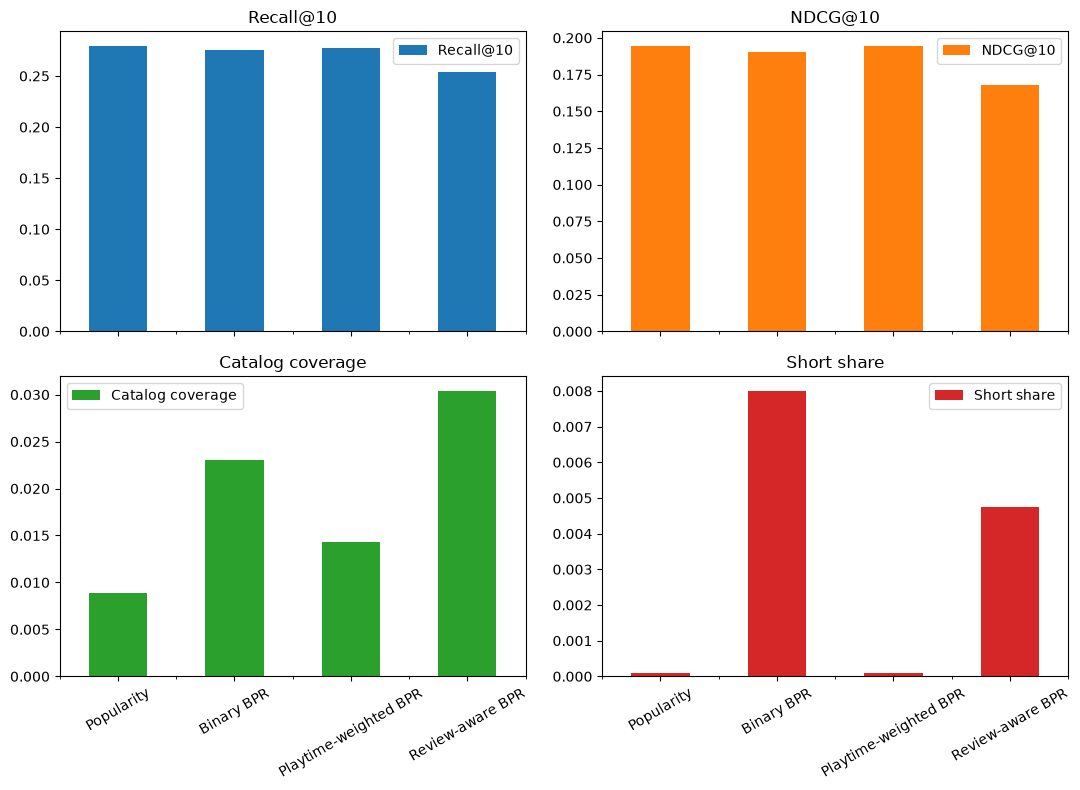

In [27]:
models = {}
curves = {}
val_results = {'Popularity':baseline_val}
for label, mode in [('Binary BPR','binary'), ('Playtime-weighted BPR','weighted'), ('Review-aware BPR','review')]:
    print('Training',label)
    models[label], curves[label] = fit_bpr(mode)
    val_results[label] = evaluate(models[label].score_users, val_eval)
validation_table = pd.DataFrame(val_results).T
print(validation_table.to_string())
validation_table[['Recall@10','NDCG@10','Catalog coverage','Short share']].plot(kind='bar',subplots=True,layout=(2,2),figsize=(11,8),rot=30)
plt.tight_layout(); plt.show()


In [28]:
test_results = {'Popularity':evaluate(popularity_scores,test_eval)}
for label,model in models.items():
    test_results[label] = evaluate(model.score_users,test_eval)
test_table = pd.DataFrame(test_results).T
print(test_table.to_string())


                       Recall@10   NDCG@10  Catalog coverage  Short share  Mean log(1+item popularity)  Users evaluated
Popularity              0.269364  0.186916          0.008837     0.000102                     9.783917           4893.0
Binary BPR              0.268343  0.186813          0.022957     0.008011                     9.735805           4893.0
Playtime-weighted BPR   0.267116  0.185790          0.014303     0.000082                     9.728168           4893.0
Review-aware BPR        0.235438  0.153489          0.030427     0.004762                     9.609856           4893.0


In [35]:
all_game_stats

,item_id,median_minutes,recommend_rate,review_count,median_hours
0,10,3469.0,0.977778,45,57.816667
1,10090,3019.0,1.0,44,50.316667
2,10130,1288.5,1.0,2,21.475000
3,10140,1003.0,1.0,1,16.716667
4,10150,810.0,1.0,9,13.500000
...,...,...,...,...,...
3077,99400,224.0,0.0,1,3.733333
3078,99700,55.0,1.0,2,0.916667
3079,99810,211.0,0.571429,7,3.516667
3080,99900,1591.0,0.911504,113,26.516667


In [36]:
print(eligible["length_group"].value_counts(dropna=False))

length_group
Medium    309
Short     155
Long      155
Name: count, dtype: int64
